# 03 — Phase 3: EDA, Lag Sweep and Reverse-Causation Check (merged)

**Purpose.** Runs the merged `sql/004_phase3_eda.sql`, which builds the quarterly decline label on the Train window only and then computes, server-side in Postgres:

1. the **lag sweep**: correlation between the decline label and the mortgage-rate change at lags of 1, 2, 3, 6, 9 and 12 months, under two alignments;
2. the **reverse-causation check**: does national price momentum lead future mortgage-rate changes (forward lags 1 to 18 months)?

This notebook then adds what SQL cannot easily give (p-values and 95% confidence intervals via the Fisher z-transformation), picks the winning lag by magnitude alone, checks its sign against the hypothesis stated in advance, and compares everything with Jolenn's pandas results.

**Decisions carried into this merged phase**

| Decision | Choice | Why |
|---|---|---|
| Rate-of-change | Percentage-point difference, `rate(t) - rate(t-lag)` | Rates are already percentages; same meaning at any rate level; Jolenn's definition |
| Alignment | Preceding quarter (label quarter *t* paired with the rate change at the end of quarter *t-1*) | "Predict one quarter ahead" must only use information known beforehand |
| Comparison alignment | Same quarter (Jolenn's EDA) | Kept only to reproduce her numbers |
| Decline threshold | Strictly more than 2% | Matches the business question |
| Missing months | Last month with a value per quarter; drop labels whose previous quarter is not the calendar quarter before | Mirrors pandas `groupby().last()` without silently labelling a gap as "no decline" |

**Prerequisites.** `003_phase2_split.sql` has run (it builds the `train_monthly` view) and `mortgage_monthly` exists. Only Train months feed the label and the lag sweep; Embargo and Test are never read.

**Expected hypothesis (stated before running).** A rising mortgage rate should make a >2% decline *more* likely, so the expected sign of the lag-sweep correlation is **positive**.

## 1. Confirm the kernel

In [1]:
import sys
import numpy as np
import pandas as pd
print(sys.executable)

d:\Capstone\capstone-housing-risk-team\.venv\Scripts\python.exe


## 2. Connect to Postgres

Same convention as notebook 02: the `housing_risk.config` helper if it exists, otherwise the `PG*` variables from `.env`.

In [2]:
import os
from pathlib import Path

from sqlalchemy import create_engine, text

try:
    from housing_risk.config import get_engine
    engine = get_engine()
except ImportError:
    from dotenv import load_dotenv, find_dotenv
    load_dotenv(find_dotenv(usecwd=True))
    engine = create_engine(
        "postgresql+psycopg2://{u}:{p}@{h}:{port}/{d}".format(
            u=os.environ["PGUSER"], p=os.environ["PGPASSWORD"],
            h=os.environ.get("PGHOST", "localhost"),
            port=os.environ.get("PGPORT", "5432"),
            d=os.environ.get("PGDATABASE", "housing_risk_team"),
        )
    )

with engine.connect() as conn:
    print(conn.execute(text("SELECT current_database(), version();")).fetchone())
    for name in ("train_monthly", "mortgage_monthly"):
        assert conn.execute(text("SELECT to_regclass(:n)"), {"n": name}).scalar(), (
            f"STOP: {name} not found -- run sql/003_phase2_split.sql (and Phase 1) first."
        )
print("train_monthly and mortgage_monthly found.")

('housing_risk_team', 'PostgreSQL 18.6 on x86_64-windows, compiled by msvc-19.44.35228, 64-bit')
train_monthly and mortgage_monthly found.


## 3. Run `004_phase3_eda.sql`

Sent through the raw DBAPI cursor with no parameters (the script has no `%` placeholders, but this keeps it identical to notebook 02). It drops and rebuilds its own tables, so it is safe to re-run.

In [3]:
def find_sql(name):
    for base in (Path("sql"), Path("..") / "sql"):
        if (base / name).exists():
            return base / name
    raise FileNotFoundError(f"{name} not found in ./sql or ../sql")


def run_sql_file(name):
    path = find_sql(name)
    raw = engine.raw_connection()
    try:
        cur = raw.cursor()
        cur.execute(open(path).read())
        raw.commit()
    except Exception:
        raw.rollback()
        raise
    finally:
        raw.close()
    print(f"ran {path}")

run_sql_file("004_phase3_eda.sql")

ran ..\sql\004_phase3_eda.sql


## 4. Check the quarterly label

Compared with the other documented figures. Small differences are expected: the SQL label keeps each county's last month *with a value* in a quarter, while the pandas EDA takes the quarter-end month only and so also loses the quarters where that month is missing.

In [4]:
label = pd.read_sql(
    "SELECT COUNT(1) AS n_rows, AVG(decline_label) AS positive_rate, "
    "COUNT(DISTINCT county_fips) AS n_counties FROM train_quarterly_labeled", engine).iloc[0]
print(f"SQL label (this notebook):   {int(label.n_rows):,} rows, {100*label.positive_rate:.2f}% positive, {int(label.n_counties):,} counties")
print("Phase 1 merged notebook:     173,734 rows, 4.93% positive")
print("Jolenn's pandas EDA:         173,277 rows, 4.88% positive")
print("Phase 0 documented figure:   173,824 rows, 4.96% positive")

SQL label (this notebook):   173,734 rows, 4.93% positive, 3,021 counties
Phase 1 merged notebook:     173,734 rows, 4.93% positive
Jolenn's pandas EDA:         173,277 rows, 4.88% positive
Phase 0 documented figure:   173,824 rows, 4.96% positive


## 5. Lag sweep with p-values and 95% confidence intervals

The SQL result gives the correlation `r` and the usable row count `n` per alignment and lag. The p-value uses the t-distribution, and the confidence interval uses the Fisher z-transformation, as in Jolenn's notebook 06.

In [5]:
from scipy import stats

def add_inference(df, r_col="correlation", n_col="n_rows"):
    df = df.copy()
    r, n = df[r_col].to_numpy(), df[n_col].to_numpy()
    t = r * np.sqrt((n - 2) / (1 - r**2))
    df["p_value"] = 2 * stats.t.sf(np.abs(t), n - 2)
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
    crit = stats.norm.ppf(0.975)
    df["ci_low"], df["ci_high"] = np.tanh(z - crit * se), np.tanh(z + crit * se)
    return df

lag = pd.read_sql(
    "SELECT alignment, lag_months, correlation, n_rows FROM lag_correlation_results "
    "ORDER BY alignment, lag_months", engine)
lag = add_inference(lag)
lag

,alignment,lag_months,correlation,n_rows,p_value,ci_low,ci_high
0,preceding quarter (used),1,-0.008400,173734,4.631208e-04,-0.013102,-0.003698
1,preceding quarter (used),2,-0.000994,173734,6.786198e-01,-0.005696,0.003708
2,preceding quarter (used),3,-0.018262,172696,3.211742e-14,-0.022976,-0.013546
3,preceding quarter (used),6,-0.023481,171651,2.254932e-22,-0.028208,-0.018752
4,preceding quarter (used),9,-0.041397,170602,1.347263e-65,-0.046133,-0.036659
5,preceding quarter (used),12,-0.050241,169548,3.444821e-95,-0.054988,-0.045492
6,same quarter (Jolenn EDA),1,-0.017870,173734,9.402549e-14,-0.022570,-0.013169
7,same quarter (Jolenn EDA),2,-0.010480,173734,1.251561e-05,-0.015182,-0.005778
8,same quarter (Jolenn EDA),3,-0.025682,173734,9.497998e-27,-0.030381,-0.020983
9,same quarter (Jolenn EDA),6,-0.030055,172696,8.210205e-36,-0.034766,-0.025342


## 6. Winning lag per alignment, and the sign check

The winner is picked by correlation magnitude alone, and the sign is checked *afterwards* against the hypothesis stated above, as a face-validity flag and not as a filter.

In [6]:
EXPECTED_SIGN = "positive"
for align, g in lag.groupby("alignment"):
    w = g.loc[g["correlation"].abs().idxmax()]
    sign = "positive" if w["correlation"] > 0 else "negative"
    print(f"{align}")
    print(f"  winning lag: {int(w['lag_months'])} months, r = {w['correlation']:.4f} "
          f"(95% CI [{w['ci_low']:.4f}, {w['ci_high']:.4f}]), n = {int(w['n_rows']):,}")
    print(f"  expected sign: {EXPECTED_SIGN}, observed: {sign}, match: {sign == EXPECTED_SIGN}")
print()
print("Caution: with n in the hundreds of thousands, even a tiny correlation has a tiny p-value. "
      "The size of r and the width of the interval say more about usefulness than the p-value.")

preceding quarter (used)
  winning lag: 12 months, r = -0.0502 (95% CI [-0.0550, -0.0455]), n = 169,548
  expected sign: positive, observed: negative, match: False
same quarter (Jolenn EDA)
  winning lag: 12 months, r = -0.0523 (95% CI [-0.0570, -0.0476]), n = 170,602
  expected sign: positive, observed: negative, match: False

Caution: with n in the hundreds of thousands, even a tiny correlation has a tiny p-value. The size of r and the width of the interval say more about usefulness than the p-value.


## 7. Comparison with Jolenn's pandas results

Jolenn's EDA pairs each label with the rate change ending in the **same quarter**, so the fair comparison is our *same quarter* alignment. The preceding-quarter rows are the one-quarter-ahead version that the merged pipeline uses.

In [7]:
JOLENN_LAG = {1: -0.017451, 2: -0.010438, 3: -0.026128, 6: -0.030357, 9: -0.036310, 12: -0.052107}  # her eda_lag_correlation.csv

pivot = lag.pivot(index="lag_months", columns="alignment", values="correlation")
compare = pivot.copy()
compare["Jolenn (pandas)"] = pd.Series(JOLENN_LAG)
compare["same-quarter SQL minus Jolenn"] = compare["same quarter (Jolenn EDA)"] - compare["Jolenn (pandas)"]
print(f"Largest gap, same-quarter SQL vs Jolenn: {compare['same-quarter SQL minus Jolenn'].abs().max():.4f}")
print("(small gaps are expected from the label differences described in section 4)")
compare.round(4)

Largest gap, same-quarter SQL vs Jolenn: 0.0004
(small gaps are expected from the label differences described in section 4)


alignment,preceding quarter (used),same quarter (Jolenn EDA),Jolenn (pandas),same-quarter SQL minus Jolenn
lag_months,,,,
1,-0.0084,-0.0179,-0.0175,-0.0004
2,-0.0010,-0.0105,-0.0104,-0.0000
3,-0.0183,-0.0257,-0.0261,0.0004
6,-0.0235,-0.0301,-0.0304,0.0003
9,-0.0414,-0.0363,-0.0363,-0.0000
12,-0.0502,-0.0523,-0.0521,-0.0002


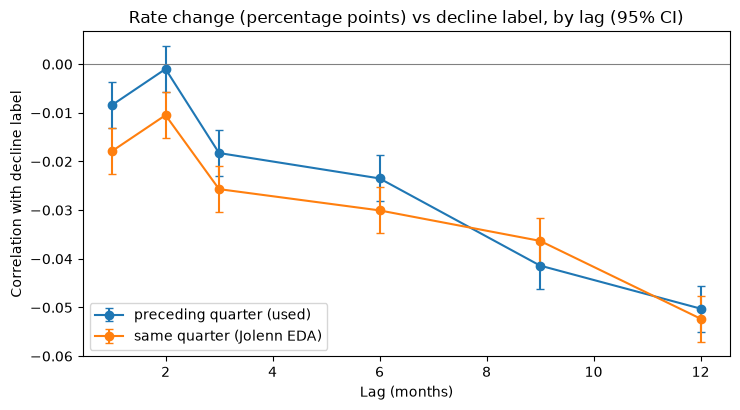

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for align, g in lag.groupby("alignment"):
    ax.errorbar(g["lag_months"], g["correlation"],
                yerr=[g["correlation"] - g["ci_low"], g["ci_high"] - g["correlation"]],
                fmt="o-", capsize=3, label=align)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Lag (months)")
ax.set_ylabel("Correlation with decline label")
ax.set_title("Rate change (percentage points) vs decline label, by lag (95% CI)")
ax.legend()
fig.tight_layout()
plt.show()

## 8. Reverse-causation check

Does national price momentum lead future mortgage-rate changes? Mirrors Jolenn's notebook 11: the 3-month change of the **median** county ZHVI at month *t* is correlated with the 1-month percentage-point change of the mortgage rate at month *t+k*, for k = 1 to 18.

- **Variant A** uses the full `mortgage_monthly` history, as her notebook does. For the latest months this reaches rate data after the end of Train.
- **Variant B** only uses rate months up to the end of Train, so no Embargo or Test period rate enters the check. It has fewer rows at long lags.

Expected sign (stated in advance): **positive**, i.e. weakening momentum followed by rate cuts.

In [9]:
rev = pd.read_sql(
    "SELECT variant, lag_months, correlation, n_rows FROM reverse_causation_sweep "
    "ORDER BY variant, lag_months", engine)
rev = add_inference(rev)

for variant, g in rev.groupby("variant"):
    w = g.loc[g["correlation"].abs().idxmax()]
    print(f"{variant}")
    print(f"  winning lag: {int(w['lag_months'])} months, r = {w['correlation']:.4f} "
          f"(95% CI [{w['ci_low']:.4f}, {w['ci_high']:.4f}]), n = {int(w['n_rows'])}")
print()
print("Jolenn (pandas): winning lag 14 months, r = 0.2637, 95% CI [0.1463, 0.3738], n = 258")

A full rate history (as Jolenn)
  winning lag: 14 months, r = 0.2637 (95% CI [0.1463, 0.3738]), n = 258
B rates through train end only
  winning lag: 4 months, r = 0.1238 (95% CI [0.0007, 0.2432]), n = 254

Jolenn (pandas): winning lag 14 months, r = 0.2637, 95% CI [0.1463, 0.3738], n = 258


In [10]:
JOLENN_REV = {1: 0.048865, 2: 0.072171, 3: 0.101193, 4: 0.145325, 5: 0.150981, 6: 0.119007,
              7: 0.099793, 8: 0.098670, 9: 0.127133, 10: 0.148220, 11: 0.161909, 12: 0.197554,
              13: 0.246026, 14: 0.263734, 15: 0.212608, 16: 0.166011, 17: 0.125971, 18: 0.091055}  # her reverse_causation_lag_sweep.csv

a = rev[rev["variant"].str.startswith("A")].set_index("lag_months")["correlation"]
b = rev[rev["variant"].str.startswith("B")].set_index("lag_months")[["correlation", "n_rows"]]
cmp_rev = pd.DataFrame({"A full history (SQL)": a, "Jolenn (pandas)": pd.Series(JOLENN_REV),
                        "B train-end rates only (SQL)": b["correlation"], "n rows (B)": b["n_rows"]})
print(f"Largest gap, variant A vs Jolenn: {(cmp_rev['A full history (SQL)'] - cmp_rev['Jolenn (pandas)']).abs().max():.6f}")
cmp_rev.round(4)

Largest gap, variant A vs Jolenn: 0.000000


,A full history (SQL),Jolenn (pandas),B train-end rates only (SQL),n rows (B)
1,0.0489,0.0489,0.0425,257
2,0.0722,0.0722,0.0618,256
3,0.1012,0.1012,0.0891,255
4,0.1453,0.1453,0.1238,254
5,0.1510,0.1510,0.1130,253
6,0.1190,0.1190,0.0563,252
7,0.0998,0.0998,-0.0016,251
8,0.0987,0.0987,-0.0284,250
9,0.1271,0.1271,-0.0121,249
10,0.1482,0.1482,0.0177,248


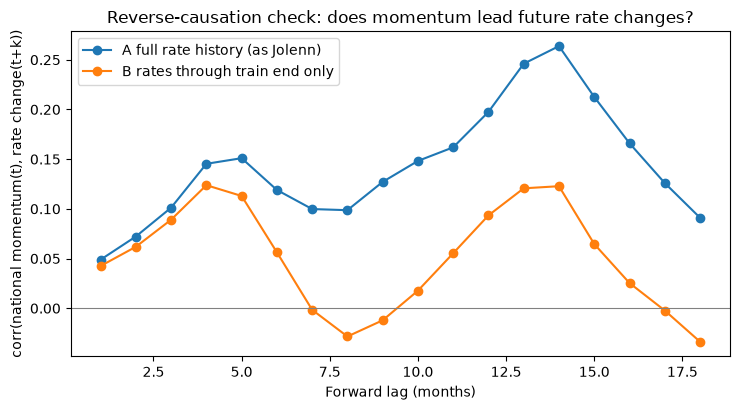

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for variant, g in rev.groupby("variant"):
    ax.plot(g["lag_months"], g["correlation"], marker="o", label=variant)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Forward lag (months)")
ax.set_ylabel("corr(national momentum(t), rate change(t+k))")
ax.set_title("Reverse-causation check: does momentum lead future rate changes?")
ax.legend()
fig.tight_layout()
plt.show()

## 9. Persist the results

Saved as CSV under `../outputs/` so the numbers are kept outside the notebook output.

In [12]:
os.makedirs("../outputs", exist_ok=True)
lag.to_csv("../outputs/phase3_lag_correlation.csv", index=False)
rev.to_csv("../outputs/phase3_reverse_causation.csv", index=False)
print("Saved outputs/phase3_lag_correlation.csv and outputs/phase3_reverse_causation.csv")

Saved outputs/phase3_lag_correlation.csv and outputs/phase3_reverse_causation.csv


## 10. Findings

- **The lag sweep reproduces Jolenn's pandas EDA.** With her same-quarter setup, our SQL matches her correlations within 0.0004 at every lag (12 months: -0.0523 against her -0.0521). The remaining gap comes from the label difference (173,734 rows against her 173,277).
- **The 12-month lag wins on both alignments.** Preceding quarter (the one-quarter-ahead version we use): r = -0.0502, 95% CI [-0.0550, -0.0455], n = 169,548. Same quarter: r = -0.0523, CI [-0.0570, -0.0476], n = 170,602. The lag choice holds up with the forward-looking alignment.
- **The sign is negative on both**, opposite to the positive sign the hypothesis expected. The effect is small (r about -0.05); the tiny p-values come from n of about 170,000.
- **Alignment matters at short lags, not long ones.** At 1 to 6 months the preceding-quarter correlations are weaker (for example -0.008 against -0.018 at 1 month), and the 2-month value is not significant (CI [-0.0057, +0.0037]). At 9 and 12 months the two alignments nearly coincide.
- **Definition matters at 12 months.** The earlier SQL used relative change (r = -0.034); percentage points give -0.050. Percentage points are carried forward.
- **Reverse causation: reproduced, but weaker than it first looks.** Variant A matches Jolenn exactly (14 months, r = 0.2637, CI [0.1463, 0.3738], n = 258). Variant B, using only rates up to the end of Train, roughly halves it: r = 0.1228 at 14 months (n = 244), and the best lag moves to 4 months (r = 0.1238, CI [0.0007, 0.2432], n = 254), with lags 7 to 9 and 17 to 18 near zero or negative. The latest 14 momentum months, paired with 2021 to 2023 rates, lift the 14-month value from about 0.12 to 0.26. Together with autocorrelation and 18 lags tried, this supports "weakly consistent with prices leading rates", not "confirmed".